# **MNIST NEURAL NETWORK**

# **Problem Statement**

# **Business Context**


 An MNIST digit-recognition model could help automate reading handwritten numbers from forms, but the notebook currently provides no evidence about model performance or business usefulness. To assess that, I’d need the model’s evaluation results—such as test accuracy, a confusion matrix, and examples of misclassified digits—plus a description of where you intend to use it.

# **Objective**


The objective of an MNIST project is to build a model that takes an image of a handwritten digit and predicts which digit it represents (0–9). In machine-learning terms, this is a **supervised, 10-class image-classification task**: the model learns from labeled examples and aims to correctly classify new, unseen images.

Its performance is typically measured by test-set accuracy, alongside a confusion matrix to show which digits are most often mistaken for one another. The attached notebook and output are empty, so I can describe the objective but can’t interpret any specific model, training setup, or results.

# **Data Description**


The **MNIST dataset** is a collection of grayscale images of handwritten digits from **0 to 9**. Each image is **28 × 28 pixels**, with each pixel representing the darkness or intensity of that part of the image. Each image is paired with a label identifying the digit.

The standard MNIST dataset contains **70,000 images**: **60,000 for training** a model and **10,000 for testing** its performance on images it has not seen during training. It is commonly used to develop and evaluate image-classification methods.

The attached notebook currently contains only the heading “Data Description,” with no dataset code or results. So this is a general description of MNIST, not a summary of the specific data loaded in the notebook.

# **Installing and Importing Necessary Libraries**

In [ ]:
!pip install --upgrade tensorflow scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import time

import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.models import Sequential
from keras.layers import Dense


These imports bring in tools for working with data, visualizing it, splitting it for evaluation, and building a neural-network model:

- `pandas as pd` — tabular data handling. The snippet imports it, though it does not show how it is used.
- `numpy as np` — numerical arrays and calculations.
- `matplotlib.pyplot as plt` and `seaborn as sns` — plotting and visualizing data or results.
- `train_test_split` — splitting data into training and testing subsets. For MNIST, the dataset may already provide these separate sets, so this helper is only needed if the code chooses to create its own split.
- `time` — measuring elapsed time, for example, how long training takes.
- `tensorflow as tf` and `from tensorflow import keras` — TensorFlow and its Keras interface for creating and training machine-learning models.
- `Sequential` — building a neural network as a linear stack of layers.
- `Dense` — adding fully connected neural-network layers.

**Small cleanup:** `Sequential` is imported twice—from `keras` and `keras.models`. You only need one import, ideally using a consistent TensorFlow Keras style, such as `from tensorflow.keras import Sequential` and `from tensorflow.keras.layers import Dense`.

In [ ]:
keras.utils.set_random_seed(812)  # Set a random seed for reproducibility

tf.config.experimental.enable_op_determinism() # Enable deterministic operations for reproducibility


`keras.utils.set_random_seed(812)` sets the random seed used by Python, NumPy, and TensorFlow. This makes randomized steps—such as neural-network weight initialization—more repeatable when the notebook is run again.

`tf.config.experimental.enable_op_determinism()` asks TensorFlow to use deterministic implementations for operations where available. This can make results more consistent across runs, though exact reproducibility may still depend on hardware, software versions, and the operations used. Deterministic execution can also reduce performance.

**In short:** these lines help make model experiments easier to repeat and compare; they do not improve the model’s accuracy by themselves.

# **Loading the data**


The `keras.datasets.mnist.load_data()` function loads the MNIST handwritten-digit dataset and separates it into training and testing sets. The training images (`x_train`) and their correct labels (`y_train`) are used to teach the model. The test images (`x_test`) and labels (`y_test`) are kept separate to evaluate how well the trained model recognizes digits it hasn’t seen before.

Each image is a 28 × 28 grayscale array, and each label is a digit from 0 to 9. In practical terms, this step provides the examples and answers the model needs for learning and evaluation.

In [ ]:
(x_train, y_train) , (x_test, y_test) = keras.datasets.mnist.load_data()


(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
```

This loads the MNIST handwritten-digit dataset and assigns it to four variables:

- **`x_train`** — training images used to teach the model.
- **`y_train`** — correct digit labels (0–9) for those training images.
- **`x_test`** — separate images used to evaluate the trained model.
- **`y_test`** — correct labels for the test images, used to check the model’s predictions.

The standard dataset contains **60,000 training images** and **10,000 test images**. Each image is a 28 × 28 grayscale pixel array. The test set is held aside so evaluation measures performance on images the model did not train on.

# **Data Overview**


The “Loading the data” section is where the MNIST dataset is brought into the notebook so it can be inspected and used for model training and evaluation. MNIST contains grayscale images of handwritten digits (0–9), each represented as a 28 × 28 grid of pixel values, with a label identifying the digit.

In the standard dataset, there are 60,000 training examples and 10,000 test examples. The training set helps the model learn patterns; the test set checks how well it recognizes unseen examples. The attached notebook only shows the section heading, so it does not include any printed shapes, samples, or other dataset-specific overview to interpret.

In [ ]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)



The output shows the number and dimensions of the MNIST images and labels:

- **`x_train.shape` → `(60000, 28, 28)`**: 60,000 training images, each 28 × 28 pixels.
- **`y_train.shape` → `(60000,)`**: one digit label for each training image.
- **`x_test.shape` → `(10000, 28, 28)`**: 10,000 test images, each 28 × 28 pixels.
- **`y_test.shape` → `(10000,)`**: one digit label for each test image.

This confirms that every image has a matching label, with the test set kept separate for evaluating how well the model performs on images it did not train on.

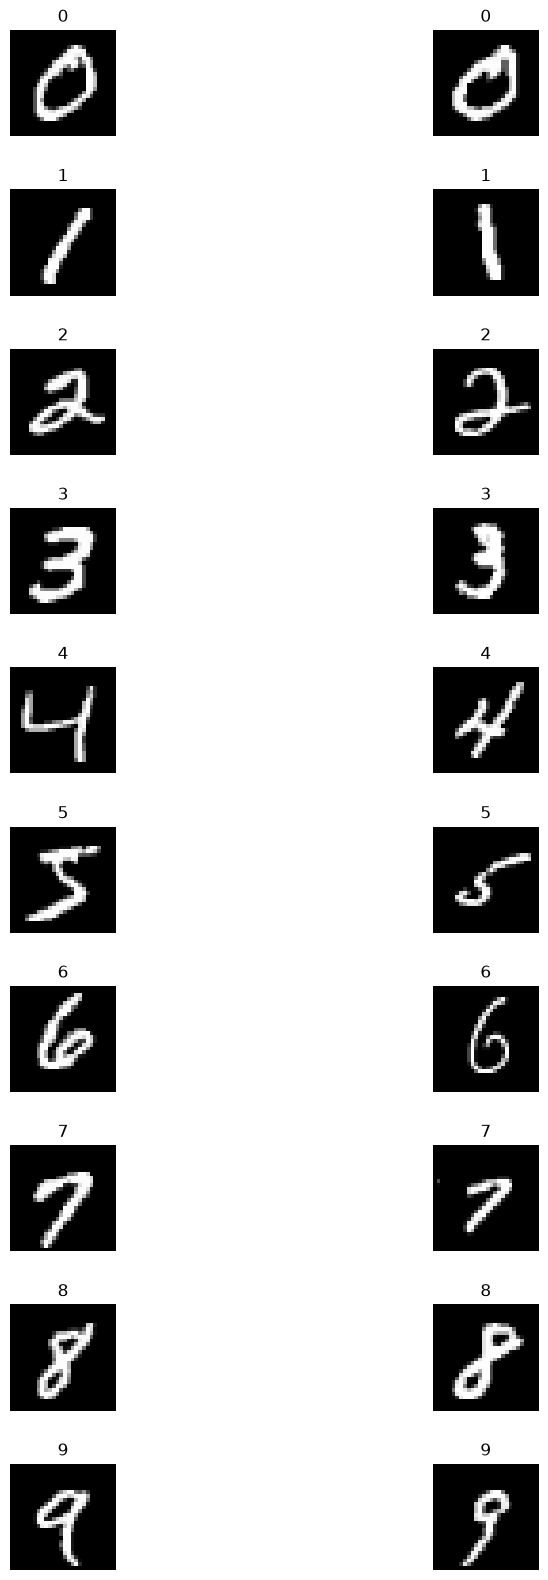

In [ ]:
f, axarr = plt.subplots(10,2,figsize=(10, 20)) #Grid of size 10*20,with 10 rows and 20 columns
for i in range(10): #for each digit from 0 to 9
    images = x_train[y_train == i] # Select images for the current digit
    axarr[i,0].imshow(images[0],cmap="gray") # Display the first image for the current digit
    axarr[i,1].imshow(images[1],cmap="gray") # Display the second image for the current digit
    axarr[i,0].axis('off') # Turn off axis for the first subplot
    axarr[i,1].axis('off') # Turn off axis for the second subplot
    axarr[i,0].set_title(str(i)) # Set title for the first subplot
    axarr[i,1].set_title(str(i)) # Set title for the second subplot

plt.subplots_adjust(hspace=0.5) # Adjust the vertical space between subplots
plt.show() # Display the subplots



This code creates a **10-row by 2-column grid** and displays two training images for each digit from 0 through 9.

For each digit `i`, `y_train == i` selects the training images labeled as that digit. The code displays the first two matching images in grayscale, hides the axes, and titles each image with its digit label. Finally, it adjusts the spacing and displays the grid.

**Purpose:** This gives a quick visual check that the images loaded correctly and shows how handwritten examples of each digit can vary. It displays only two examples per digit—not the entire dataset or a statistical summary.

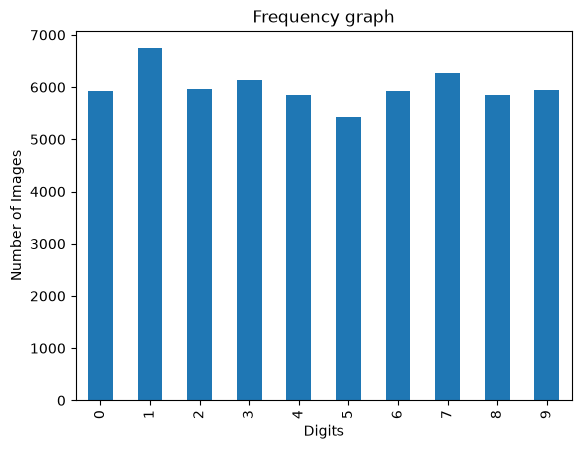

In [ ]:
# frequency graph of the distribution of digit classes in the training set
(pd.Series(y_train).value_counts())[[0,1,2,3,4,5,6,7,8,9]].plot.bar()# Plot a bar chart of the distribution of digit classes in the training set
plt.title("Frequency graph") #Setting the title of the plot
plt.xlabel("Digits") #Setting the x-axis label
plt.ylabel("Number of Images") #Defining the y-axis label
plt.show() # Display the plot


The bar chart shows how many training images belong to each digit class (0–9). MNIST’s training classes are **fairly balanced**, though not exactly equal: digit **1** has the most examples (about 6,742), while digit **5** has the fewest (about 5,421).

This means the model has examples of every digit and is unlikely to be dominated by a single class. The difference is worth keeping in mind when evaluating performance: accuracy alone can hide weak results for a less frequent digit, so class-by-class metrics or a confusion matrix can provide a fuller picture.

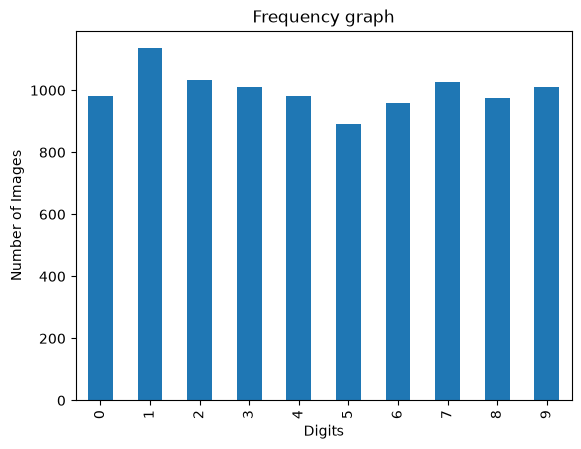

In [ ]:
# frequency graph of the disribution of digit classes in the training set
(pd.Series(y_test).value_counts())[[0,1,2,3,4,5,6,7,8,9]].plot.bar()# Plot a bar chart of the distribution of digit classes in the training set
plt.title("Frequency graph") #Setting the title of the plot
plt.xlabel("Digits") #Setting the x-axis label
plt.ylabel("Number of Images") #Defining the y-axis label
plt.show() # Display the plot


This code counts the labels in **`y_test`** and plots how many test images belong to each digit from 0 to 9. Although the comments say “training set,” the code is actually visualizing the **test set**.

The bars are roughly similar in height, indicating that the test data includes a fairly balanced number of examples for each digit. This helps check whether evaluation covers all classes reasonably evenly. For a clearer chart, update the comments and title to say **“test set”**; use `y_train` instead if you intended to chart the training data.

# **Data pre-processing**


Data preprocessing prepares the MNIST images and labels so they can be used by a machine-learning model. Common steps include scaling pixel values from **0–255 to 0–1**, which can help a neural network train more effectively, and formatting the image arrays to match the model’s expected input. Labels may also be converted to a suitable format, depending on the model and loss function.

The attached notebook shows only the **“Data pre-processing”** heading, not the code beneath it, so I can’t confirm which steps your notebook actually performs.

***Data preparation for modeling***

In [ ]:
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=1-(5/6), random_state=42,stratify=y_train) # Split the training data into training and validation sets


This line splits the existing training data into two parts:

- **Training set (`x_train`, `y_train`)**: about **83.3%** of the original training data, used to fit the model.
- **Validation set (`x_val`, `y_val`)**: about **16.7%**, used to monitor performance and guide choices such as model settings, without using the separate test set.

`stratify=y_train` keeps the digit proportions approximately balanced in both subsets. `random_state=42` makes the split reproducible. The original MNIST test set remains separate for final evaluation.

In [ ]:
#print the shapes of the training and validation sets
print(x_train.shape, y_train.shape)
print(x_val.shape, y_val.shape)

(50000, 28, 28) (50000,)
(10000, 28, 28) (10000,)



The printed shapes confirm that the original 60,000 MNIST training examples were split into:

- **Training set:** 50,000 images of size 28 × 28, with 50,000 corresponding labels.
- **Validation set:** 10,000 images of size 28 × 28, with 10,000 corresponding labels.

Each image has a matching digit label. The model learns from the 50,000 training examples, while the 10,000 validation examples help monitor its performance during development.

# **Data Scaling**


Data scaling typically converts MNIST pixel values from **0–255** to a smaller range, often **0–1**, by dividing each pixel value by 255. This gives the model consistently sized inputs and can help neural-network training behave more smoothly.

The attached notebook section is empty, so I can’t verify the exact scaling code or confirm whether scaling is applied to the training, validation, and test images.

In [ ]:
print(x_train.max(),x_test.max(),x_val.max()) # Print the maximum pixel values in the training, testing, and validation sets
print(x_train.min(),x_test.min(),x_val.min()) # Print the minimum pixel values in the training, testing, and validation sets

255 255 255
0 0 0



These commands print the **largest** and **smallest** pixel values in the training, test, and validation image sets.

The output shows that all three sets range from **0 to 255**, which is the usual raw grayscale pixel range: 0 represents black and 255 represents the brightest pixel. This confirms that the images have **not yet been scaled to 0–1**. If the model expects scaled inputs, divide the image arrays by 255 before training and apply the same scaling to validation and test data.

In [ ]:
# Normalizing the dataset
x_train, x_val, x_test = x_train.astype("float32")/(225), x_val.astype("float32")/(225), x_test.astype("float32")/(225)


This code converts the training, validation, and test images to 32-bit floating-point values, then divides their pixel values by **225**. This is intended to scale the images before feeding them to a neural network.

**Important:** MNIST pixel values range from 0 to **255**, so dividing by 225 can produce values as high as **255 / 225 ≈ 1.13**—not the usual 0–1 range. Use **255** as the divisor instead:

```python
x_train, x_val, x_test = (
    x_train.astype("float32") / 255.0,
    x_val.astype("float32") / 255.0,
    x_test.astype("float32") / 255.0,
)
```
This scales all three datasets consistently to the range **0–1**.

In [ ]:
print(x_train.max(),x_test.max(),x_val.max()) # Print the maximum pixel values in the training, testing, and validation sets
print(x_train.min(),x_test.min(),x_val.min()) # Print the minimum pixel values in the training, testing, and validation sets

1.1333333 1.1333333 1.1333333
0.0 0.0 0.0



These commands check the maximum and minimum pixel values in the training, test, and validation sets after scaling. The output shows a range of **0.0 to 1.1333** for all three sets.

The minimum is as expected, but the maximum is greater than 1. This confirms the images were divided by **225** rather than **255**. For the usual 0–1 normalization range, divide each image array by `255.0`.

# **Re-shaping**


Reshaping changes the **format** of the MNIST images to match the model’s expected input; it does not change the pixel values or the digit labels.

For a fully connected (`Dense`) network, each 28 × 28 image is often flattened into a vector of **784 pixel values**. The dataset shape changes from `(number_of_images, 28, 28)` to `(number_of_images, 784)`. For a convolutional network, images are usually kept as 28 × 28 and given a channel dimension, resulting in `(number_of_images, 28, 28, 1)`.

The attached notebook section is empty, so I can’t tell which reshaping approach your code uses.

In [ ]:
# Reshaping the image data 
x_train = x_train.reshape(x_train.shape[0],-1) 
x_val = x_val.reshape(x_val.shape[0],-1) 
x_test = x_test.reshape(x_test.shape[0],-1)


These lines flatten each 28 × 28 image into a one-dimensional vector, separately for the training, validation, and test sets.

- `x_train.shape[0]` keeps the number of training images unchanged.
- `-1` tells NumPy to infer the remaining dimension, which becomes **784** pixels per image.

So, for example, the training images change from `(50000, 28, 28)` to `(50000, 784)`. The pixel values themselves are not changed. This format is suitable for a fully connected (`Dense`) neural network.

In [ ]:
print(x_train.shape[0], "train samples")
print(x_val.shape[0], "validation samples")
print(x_test.shape[0], "test samples")

50000 train samples
10000 validation samples
10000 test samples



`shape[0]` retrieves the number of images in each dataset. The output shows:

- **50,000 training samples** used to teach the model.
- **10,000 validation samples** used to monitor and tune the model during development.
- **10,000 test samples** reserved for evaluating the final model on unseen data.

Together, these account for all **70,000 MNIST images**: the original 60,000 training images were split into training and validation subsets, and the original 10,000 test images remain separate.

# **Encoding the target variable**


The target variable is the digit label (`y_train`, `y_val`, or `y_test`) that the model is expected to predict. Encoding means representing those labels in a format compatible with the model and its loss function.

For MNIST, labels are already integers from **0 to 9**. They can remain integers when using a sparse categorical loss, or be converted to **one-hot vectors** when using a categorical loss—for example, digit `3` becomes a vector with ten entries and a `1` in the position for class 3.

The attached content doesn’t show the encoding code, so I can’t tell which format this notebook uses.

In [ ]:
num_classes = 10 # Number of classes in the dataset


`num_classes = 10` sets the number of categories the model must distinguish. For MNIST, these are the ten digit classes: **0 through 9**. This value may be used when defining the model’s output layer—for example, to produce one score or probability for each digit.

In [ ]:
y_train = keras.utils.to_categorical(y_train, num_classes)
y_val = keras.utils.to_categorical(y_val, num_classes) 
y_test = keras.utils.to_categorical(y_test, num_classes) 


These lines convert each digit label in the training, validation, and test sets into a **10-element one-hot vector**, because `num_classes` is 10.

For example, the label `3` becomes `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`. The `1` marks the correct digit class, and the zeros mark the others. This format is commonly used with a model that outputs ten class scores and is trained with **categorical cross-entropy**.

After conversion, each target array has an additional class dimension—for example, `y_train` changes from shape `(50000,)` to `(50000, 10)`.

In [ ]:
y_train

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.]], shape=(50000, 10))


`y_train` contains the **correct digit labels** for the 50,000 training images. Since the labels were converted using one-hot encoding, it is now a **50,000 × 10 array**:

- Each row corresponds to one training image.
- The 10 entries represent digit classes **0–9**.
- The entry with value `1` identifies the correct digit; the remaining entries are `0`.

For example, a row with `1` in the fourth position represents digit **3** (counting from position 0). The model uses these encoded labels as the correct answers during training.

In [ ]:
#Defining the columns for the results dataframe which is nothing but the hyperparameters and the metrics we want to track during training and validation.
columns =("hidden layers","neurons - hidden layers","activation function - hidden layers","epochs","batch size","train loss","validation loss","train accuracy","validation accuracy","time(secs)")

#Creating a pandas dataframe.
results = pd.DataFrame(columns=columns)


This code creates an empty pandas table named `results` to record and compare model experiments.

Its columns include:

- **Model settings (hyperparameters):** number of hidden layers, neurons per layer, activation function, epochs, and batch size.
- **Performance metrics:** training and validation loss, and training and validation accuracy.
- **Runtime:** training time in seconds.

Each row can later store the settings and results from one training run. This makes it easier to compare different model configurations and see how their performance and training time differ.

# **Model 0**

In [ ]:
import gc
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()
gc.collect() 

0


- `import gc` loads Python’s garbage-collection module.
- `tf.keras.backend.clear_session()` clears Keras’s internal state, such as model-building information and layer name counters. It’s useful before building another model or repeating experiments, to reduce leftover state.
- `gc.collect()` asks Python to reclaim objects that are no longer in use.

The output `0` means Python did not collect any unreachable objects during that call; it does not indicate an error. The TensorFlow deprecation warning is informational and does not prevent the cleanup call from running.

In [ ]:
# Initializing the neural network 
model = Sequential() 
# Add a dense layer with softmax activation for multi-class classification
model.add(Dense(num_classes, activation='softmax', input_dim=x_train.shape[1]))


`model = Sequential()` creates a neural network whose layers are added in order.

The `Dense` layer has **10 output units**, one for each MNIST digit class (0–9). Its input size, `x_train.shape[1]`, is the number of features per image—**784** after each 28 × 28 image has been flattened. The `softmax` activation converts the outputs into scores that can be interpreted as probabilities across the ten digit classes.

As written, this model has **only an output layer**, with no hidden layers. It therefore learns a direct mapping from the 784 input pixel values to the 10 digit classes.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` prints a compact overview of the neural network’s structure and size. The output shows:

- **One `Dense` layer** with an output shape of `(None, 10)`. `None` means the model can process a variable number of images in a batch; `10` is one output for each digit class.
- **7,850 parameters**, all trainable. With 784 input pixels and 10 output units, this is 7,840 weights plus 10 biases.

This confirms the current model is a simple, single-layer classifier with no hidden layer.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy']) 


`model.compile(...)` configures how the neural network will learn and how its performance will be measured:

- **`loss='categorical_crossentropy'`** measures the difference between the model’s predicted class probabilities and the one-hot encoded correct labels.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** asks Keras to report the proportion of correctly classified examples during training and evaluation.

These settings are consistent with the model’s 10-way softmax output and the one-hot encoded labels. The model is configured here, but it won’t train until `model.fit(...)` is called.

In [ ]:
batch_size = x_train.shape[0]
epochs = 10

# Record the start time of training
start_time = time.time() 

#fitting the model
history =model.fit(x_train, y_train,validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time() 

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0592 - loss: 2.4630 - val_accuracy: 0.0632 - val_loss: 2.4420
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step - accuracy: 0.0627 - loss: 2.4451 - val_accuracy: 0.0673 - val_loss: 2.4245
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.0670 - loss: 2.4276 - val_accuracy: 0.0726 - val_loss: 2.4074
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.0716 - loss: 2.4105 - val_accuracy: 0.0771 - val_loss: 2.3907
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.0768 - loss: 2.3937 - val_accuracy: 0.0824 - val_loss: 2.3743
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.0824 - loss: 2.3773 - val_accuracy: 0.0907 - val_loss: 2.3582
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step - accuracy: 0.0890 - loss: 2.3611 - val_accuracy: 0.0971 - val_loss: 2.3424
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 657ms/step - accuracy: 0.0951 - loss: 2.3453 - val_accuracy: 0.1023 - val_loss: 2.


- `batch_size = x_train.shape[0]` sets the batch size to **50,000**, the entire training set. The output confirms **one update step per epoch**.
- `epochs = 10` trains the model over the training data ten times.
- `model.fit(...)` trains on `x_train` and `y_train`, checks performance on `x_val` and `y_val` after each epoch, and stores the results in `history`.
- `start_time` and `end` record timestamps; subtract them (`end - start_time`) to calculate the training duration.

**What the results show:** Training accuracy rises from **5.9% to 11.0%**, and validation accuracy from **6.3% to 11.9%**. Both losses decrease, so the model is learning gradually. However, validation accuracy is still only slightly above the **10% chance level** for ten balanced classes, indicating weak performance after these ten epochs. The full-dataset batch means only one weight update each epoch; smaller batches would provide more updates and may help training progress.

In [ ]:
results.loc[0]=[0,'-', '-', 10, 50000,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],end-start_time]


This line adds the model’s results as **row 0** in the `results` DataFrame. It records:

- **`0`** — the experiment or model identifier.
- **`'-'` values** — placeholders for hidden-layer settings, since this model has no hidden layers.
- **`10` epochs** and **`50000` batch size** — the training configuration.
- The final training and validation **loss** and **accuracy**, taken from the last epoch in `history`.
- **`end - start_time`** — the elapsed training time in seconds.

This creates a compact record that can be compared with results from later model configurations.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.1101,0.1191,6.221472



The table summarizes the model’s first training run:

- **Architecture:** 0 hidden layers; it is a single softmax output layer.
- **Training setup:** 10 epochs with a batch size of 50,000.
- **Final loss:** 2.315 on training data and 2.297 on validation data.
- **Final accuracy:** 11.01% on training data and 11.91% on validation data.
- **Training time:** about 6.22 seconds.

The training and validation results are close, so there is no obvious sign of overfitting in this run. However, accuracy around 12% is low for a 10-class digit task (about 10% is chance-level), so this baseline model has learned little so far. Consider testing smaller batches and a model with hidden layers, then compare the validation results.

# **Model 1**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()


*`tf.keras.backend.clear_session()` clears Keras’s internal model-building state before you create another model. This helps keep repeated experiments separate and can reduce leftover framework state or resource use.

It does **not** erase your dataset or the saved `results` table, but it does reset Keras’s state; use it after you have finished with the current model.*

In [ ]:
# Initializing the neural network 
model = Sequential()
# Add a dense layer with softmax activation for multi-class classification
model.add(Dense(num_classes, activation='softmax', input_dim=x_train.shape[1]))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



`Sequential()` creates a model whose layers are arranged in order. The `Dense` layer maps each flattened image (784 pixel inputs) to **10 output values**, one for each digit from 0 to 9. `softmax` turns those outputs into class probabilities; the model’s predicted digit is the class with the highest probability.

This is a **single-layer classifier** with no hidden layers. The output also shows a Keras warning: in a `Sequential` model, it is now preferred to specify the input with an explicit `Input` layer, for example:

```python
model = Sequential([
    keras.Input(shape=(x_train.shape[1],)),
    Dense(num_classes, activation="softmax")
])
```

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)


The summary confirms the model has **one Dense layer** with an output shape of `(None, 10)`. Each input image is represented by **784 pixel values**, and the model produces 10 outputs—one for each digit class. `None` means the model can accept batches of different sizes.

The layer has **7,850 trainable parameters**: 7,840 weights (784 inputs × 10 outputs) and 10 bias values. There are no hidden layers, and all parameters can be updated during training.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])


`model.compile(...)` configures the model for training:

- **`categorical_crossentropy`** is the loss function. It measures how far the model’s predicted probabilities are from the correct one-hot encoded digit labels.
- **`sgd`** selects stochastic gradient descent to update the model’s weights to reduce that loss.
- **`accuracy`** tells Keras to report the fraction of predictions that match the correct digit.

These settings match a 10-class softmax output with one-hot labels. Compilation sets up training; the model learns when you call `model.fit(...)`.

In [ ]:
batch_size = x_train.shape[0]
epochs = 50

# Record the start time of training
start = time.time()  

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time() 

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0876 - loss: 2.5040 - val_accuracy: 0.0895 - val_loss: 2.4855
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.0905 - loss: 2.4845 - val_accuracy: 0.0922 - val_loss: 2.4667
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.0937 - loss: 2.4657 - val_accuracy: 0.0941 - val_loss: 2.4485
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.0968 - loss: 2.4473 - val_accuracy: 0.0973 - val_loss: 2.4308
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.0999 - loss: 2.4295 - val_accuracy: 0.1002 - val_loss: 2.4136
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.1040 - loss: 2.4122 - val_accuracy: 0.1042 - val_loss: 2.3968
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.1078 - loss: 2.3953 - val_accuracy: 0.1091 - val_loss: 2.3805
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step - accuracy: 0.1122 - loss: 2.3789 - val_accuracy: 0.1140 - val_loss: 2.


`batch_size = x_train.shape[0]` sets the batch size to **50,000**, so the model processes the entire training set in one batch per epoch. `epochs = 50` asks Keras to make 50 passes over the training data, checking performance on the validation set after each pass.

`history` stores the training and validation loss and accuracy for those epochs. `start` and `end` capture timestamps; subtracting them (`end - start`) gives the elapsed training time in seconds.

**Important:** If you run this after the earlier 10-epoch `model.fit(...)` without rebuilding or reinitializing the model, training continues from its existing weights for **50 additional epochs**—60 epochs of training in total. The new `history` variable contains metrics for this latest 50-epoch call.

In [ ]:
results.loc[1]=[0,'-', '-', 50, 50000,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]    


This line adds a second experiment record at **row 1** of the `results` DataFrame. It stores the model setup—0 hidden layers, 50 epochs, and a batch size of 50,000—along with the final training and validation loss and accuracy from `history`.

`round(end - start, 2)` records the elapsed training time in seconds, rounded to two decimal places. If the model was not reset before the 50-epoch fit, this row describes the results after **50 additional epochs of training**, not a fresh model trained for only 50 epochs.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000



The table compares the same simple model trained with two epoch settings:

- **10 epochs:** training accuracy was **11.01%** and validation accuracy **11.91%**.
- **50 epochs:** training accuracy increased to **50.69%** and validation accuracy to **51.32%**. Training and validation loss also fell from about **2.31 / 2.30** to **1.87 / 1.87**.
- The 50-epoch run took **17.08 seconds**, compared with **6.22 seconds** for the 10-epoch run.

So, training longer substantially improved this baseline model, and the similar training and validation scores do not suggest obvious overfitting. However, roughly **51% validation accuracy is still limited** for MNIST. Also, if the 50-epoch run continued training the same model after its 10-epoch run, it represents 50 additional epochs rather than an independent 50-epoch comparison.

# **Model 2**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` resets Keras’s internal state before building the next model. This is useful when running multiple experiments because it prevents model-building state from carrying over and can help release resources.

It does **not** clear your data or the `results` DataFrame. After calling it, create a new model; the previous model should no longer be treated as the active Keras model.

In [ ]:
# Initializing the neural network
model = Sequential()
# Add a dense layer with softmax activation for multi-class classification
model.add(Dense(num_classes, activation='softmax', input_dim=x_train.shape[1]))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a new **Sequential** neural network and adds a single fully connected (`Dense`) output layer. It accepts each flattened MNIST image as **784 pixel inputs** and produces **10 outputs**, one for each digit class (0–9). The `softmax` activation converts the outputs into probabilities across those classes.

Because there are no hidden layers, this is a simple baseline classifier rather than a deeper neural network. The output also contains a Keras warning: for newer Keras versions, prefer defining the input explicitly with `keras.Input(shape=(x_train.shape[1],))`.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)


The output shows that the model contains **one Dense layer** with an output shape of `(None, 10)`: it produces ten outputs, one for each digit class. `None` indicates the model can process different batch sizes.

It has **7,850 trainable parameters**—7,840 weights connecting the 784 input pixels to 10 output units, plus 10 bias values. There are no hidden layers, so this is a simple single-layer classifier.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])


This code **configures** the neural network for training:

- **`loss='categorical_crossentropy'`** measures the difference between predicted digit probabilities and the correct one-hot labels.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** tells Keras to report the fraction of correctly classified images.

These settings suit a 10-class softmax output and one-hot encoded labels. The model is ready to train, but this line does not train it; training starts with `model.fit(...)`.

In [ ]:
batch_size = 32
epochs = 10

# Record the start time of training
start = time.time()

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/10


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8141 - loss: 0.7625 - val_accuracy: 0.8720 - val_loss: 0.5030
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8814 - loss: 0.4502 - val_accuracy: 0.8866 - val_loss: 0.4242
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8912 - loss: 0.3989 - val_accuracy: 0.8938 - val_loss: 0.3915
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8973 - loss: 0.3731 - val_accuracy: 0.8972 - val_loss: 0.3725
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9007 - loss: 0.3567 - val_accuracy: 0.9000 - val_loss: 0.3598
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9042 - loss: 0.3451 - val_accuracy: 0.9021 - val_loss: 0.3506
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9064 - loss: 0.3362 - val_accuracy: 0.9036 - val_loss: 0.3435
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9084 - loss: 0.3291 - val_accura


This code trains the model for **10 epochs**, using mini-batches of **32 images**. With 50,000 training images, that gives about **1,563 update steps per epoch**. The validation set is evaluated after each epoch, and `history` stores the loss and accuracy values. `start` and `end` record timestamps, so `end - start` gives the total training time.

**Results:** Training accuracy rose from about **81.4% to 91.1%**, while validation accuracy rose from **87.2% to 90.9%**. Training and validation loss both decreased, ending at **0.318** and **0.329**. The close final metrics suggest the model is learning and there is no strong sign of overfitting in these 10 epochs. The validation accuracy is promising for this simple classifier, but final generalization should be checked on the separate test set.

In [ ]:
results.loc[2]=[0,'-', '-',10,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   


This line stores the latest training run as **row 2** in the `results` DataFrame. It records a model with **0 hidden layers**, trained for **10 epochs** with a **batch size of 32**, along with its final training and validation loss and accuracy. The training time is recorded in seconds, rounded to two decimal places.

Based on the preceding training output, this row should show about **91.11% training accuracy** and **90.85% validation accuracy**, with losses of approximately **0.318** and **0.329**. The DataFrame output itself is empty here, so those figures are inferred from the previous epoch log rather than verified in this cell.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000



Model 2 is the **same single-layer classifier** (0 hidden layers), but trained for 10 epochs with a much smaller batch size of **32**.

- **Training accuracy:** 91.11%
- **Validation accuracy:** 90.85%
- **Training loss:** 0.318
- **Validation loss:** 0.329
- **Training time:** 74.39 seconds

Compared with the 10-epoch run using a batch size of 50,000, the batch-32 run performed much better: validation accuracy rose from **11.91% to 90.85%** and validation loss fell from **2.297 to 0.329**. The training and validation metrics are close, suggesting no strong overfitting in this run. The tradeoff is longer training time. This comparison suggests that smaller batches gave the optimizer many more weight updates per epoch, which helped the model learn effectively.

# **Model 3**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` resets Keras’s internal state before the next model is created. This is helpful when running multiple experiments: it prevents old model-building state from carrying over and can reduce unnecessary resource use.

It does **not** clear the MNIST data or your `results` DataFrame. After calling it, define a new model before training again.

In [ ]:
# Initializing the neural network
model = Sequential()
# Add a dense layer with softmax activation for multi-class classification
model.add(Dense(num_classes, activation='softmax', input_dim=x_train.shape[1]))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code initializes a new **Sequential** neural network and adds one fully connected (`Dense`) output layer. Each flattened MNIST image provides **784 input values**, and the layer produces **10 outputs**, one for each digit (0–9). The `softmax` activation turns these outputs into probabilities across the ten classes.

There are no hidden layers, so this is a simple baseline classifier. The notebook output also shows a Keras warning because `input_dim` is specified inside `Dense`; newer Keras code prefers an explicit input layer, for example:

```python
model = Sequential([
    keras.Input(shape=(x_train.shape[1],)),
    Dense(num_classes, activation="softmax")
])
```

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` shows the model’s architecture and parameter counts. It contains **one Dense layer** that outputs 10 values—one per digit class. The `None` in `(None, 10)` means it can process any batch size.

The layer has **7,850 trainable parameters**: 7,840 weights connecting the 784 input pixels to the 10 output units, plus 10 bias values. There are no hidden layers, so this is a single-layer classifier.

In [ ]:
#Compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

This line configures the model for training:

- **`categorical_crossentropy`** measures how different the predicted class probabilities are from the correct one-hot digit labels.
- **`sgd`** (stochastic gradient descent) updates the model’s weights to reduce that loss.
- **`accuracy`** asks Keras to report the percentage of predictions that match the correct digit.

These choices fit a 10-class softmax output with one-hot encoded labels. Compiling prepares the model; `model.fit(...)` performs the training.

In [ ]:
batch_size=32
epochs=50

# Record the start time of training
start = time.time()  

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8217 - loss: 0.7523 - val_accuracy: 0.8696 - val_loss: 0.4972
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8824 - loss: 0.4466 - val_accuracy: 0.8860 - val_loss: 0.4213
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8922 - loss: 0.3967 - val_accuracy: 0.8935 - val_loss: 0.3895
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8976 - loss: 0.3714 - val_accuracy: 0.8986 - val_loss: 0.3710
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9009 - loss: 0.3553 - val_accuracy: 0.9009 - val_loss: 0.3586
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9038 - loss: 0.3438 - val_accuracy: 0.9027 - val_loss: 0.3495
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9068 - loss: 0.3350 - val_accuracy: 0.9035 - val_loss: 0.3425
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9088 - loss: 0.3281 -


This trains the model for **50 passes** over the training set, processing **32 images per batch**—about **1,563 batches per epoch**. Validation performance is checked after each epoch and saved in `history`. `start` and `end` capture timestamps; `end - start` gives the total training time in seconds.

**Results:** Training accuracy rose to **92.57%**, and validation accuracy reached **91.83%**. Training and validation loss decreased to **0.267** and **0.293**. Validation accuracy peaked around **91.85%** near epoch 48, then stayed roughly level. The close training and validation scores show no strong evidence of overfitting; the small late-epoch plateau suggests the model’s improvement was slowing. These are validation results, not the final test-set performance.

In [ ]:
results.loc[3]=[0,'-', '-',50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   


This line records the **50-epoch, batch-size-32** run as row **3** in the `results` DataFrame. It stores the model configuration, the final training and validation loss and accuracy from `history`, and the elapsed training time rounded to two decimal places.

Based on the preceding training log, the recorded metrics should be approximately **92.57% training accuracy**, **91.83% validation accuracy**, training loss **0.2670**, and validation loss **0.2927**. The output for this cell is empty, so these values are inferred from the epoch log rather than confirmed from the table.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000



The attached content shows the code that records **Model 3** (row 3 of the results table), but not the displayed table itself. From the preceding 50-epoch training log, Model 3 appears to be the same single-layer classifier trained for **50 epochs** with a **batch size of 32**.

It reached **92.57% training accuracy** and **91.83% validation accuracy**, with losses of approximately **0.267** and **0.293**. The close accuracy and loss values suggest no strong overfitting. Validation accuracy was nearly flat in the final epochs, indicating that improvement had slowed.

These figures are inferred from the training log; the table output was not included in the attachment.

# **Model 4**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` resets Keras’s internal state before you build the next model. It’s useful when running multiple experiments, helping avoid leftover model-building state and potentially reducing resource use.

It does not delete the MNIST data or your `results` DataFrame. After clearing the session, create a new model before training again.

In [ ]:
# Initializing the neural network
model = Sequential()
# Add a dense layer with softmax activation for multi-class classification
model.add(Dense(num_classes, activation='softmax', input_dim=x_train.shape[1]))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a new **Sequential** neural network and adds one fully connected output layer. Each flattened MNIST image contributes **784 input features**, and the layer produces **10 outputs**, one for each digit from 0 to 9. The `softmax` activation converts the outputs into probabilities; the highest probability is the model’s predicted digit.

Because there are no hidden layers, this is a simple single-layer classifier. The notebook output also shows a Keras warning: newer Keras versions recommend defining the input with an explicit `keras.Input(shape=(x_train.shape[1],))` layer.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` reports the network structure and parameter counts. This model has **one Dense layer** with an output shape of `(None, 10)`: it produces ten outputs, one for each digit class. `None` means the model can process different batch sizes.

The layer contains **7,850 trainable parameters**: 7,840 weights connecting the 784 pixel inputs to the 10 outputs, plus 10 bias values. There are no hidden layers, so it is a simple single-layer classifier.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

This line configures the model for training:

- **`categorical_crossentropy`** measures the difference between the predicted probabilities and the correct one-hot digit labels.
- **`sgd`** (stochastic gradient descent) adjusts the model’s weights to reduce that loss.
- **`accuracy`** tells Keras to track the fraction of images classified correctly.

These settings match the model’s 10-class softmax output and one-hot encoded labels. Compilation prepares the model; training begins when `model.fit(...)` runs.

In [ ]:
batch_size=64
epochs=50

# Record the start time of training
start = time.time()  

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7740 - loss: 0.9708 - val_accuracy: 0.8535 - val_loss: 0.6216
Epoch 2/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8661 - loss: 0.5447 - val_accuracy: 0.8734 - val_loss: 0.4987
Epoch 3/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8795 - loss: 0.4667 - val_accuracy: 0.8815 - val_loss: 0.4493
Epoch 4/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8869 - loss: 0.4287 - val_accuracy: 0.8885 - val_loss: 0.4213
Epoch 5/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8913 - loss: 0.4052 - val_accuracy: 0.8925 - val_loss: 0.4027
Epoch 6/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8950 - loss: 0.3888 - val_accuracy: 0.8948 - val_loss: 0.3892
Epoch 7/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8972 - loss: 0.3764 - val_accuracy: 0.8963 - val_loss: 0.3789
Epoch 8/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8994 - loss: 0.3666 - val_accuracy: 0.


This trains the model for **50 epochs**, using batches of **64 images**—about **782 batches per epoch** for 50,000 training images. After each epoch, Keras evaluates performance on the validation set. `history` stores the metrics, and `end - start` gives the total training time in seconds.

At epoch 50, the output reports **92.05% training accuracy** and **91.54% validation accuracy**, with losses of **0.284** and **0.304**, respectively. The training and validation results are fairly close, suggesting no large train–validation gap. Validation accuracy has mostly plateaued near the end, so further epochs may yield only small improvements.

If this was run on an existing model without rebuilding it, training continued from its current weights.

In [ ]:
results.loc[4]=[0,'-', '-',50,64,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   

This line saves the latest run as **row 4** in the `results` DataFrame. It records the model configuration—**0 hidden layers**, **50 epochs**, and **batch size 64**—along with the final training and validation loss and accuracy from `history`. The elapsed time is stored in seconds, rounded to two decimal places.

From the training output, the final metrics are approximately **92.05% training accuracy**, **91.54% validation accuracy**, training loss **0.2841**, and validation loss **0.3037**. The cell’s output is empty, so these numbers are taken from the preceding training log, not directly from a displayed table.

In [ ]:
results 

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000



Model 4 is the same single-layer classifier, trained for **50 epochs** with a **batch size of 64**. It achieved **92.05% training accuracy** and **91.54% validation accuracy**, with losses of **0.284** and **0.304**.

The training and validation scores are close, so there is no large gap suggesting overfitting. Compared with the 50-epoch run using batch size 32 (about **91.83% validation accuracy**), batch size 64 produced a slightly lower validation accuracy (**91.54%**). This is a small difference; compare training time as well before deciding which configuration is preferable. These are validation results, not the final test-set score.

# **Model 5**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` resets Keras’s internal state before you build another model. This is useful for keeping repeated experiments separate and may help release resources used by previous models.

It does **not** erase your MNIST datasets or the `results` DataFrame. After calling it, define a new model before training again.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(64, activation='sigmoid', input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation = 'softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



This code builds a two-layer neural network:

- The first `Dense` layer is a **hidden layer with 64 neurons**. Each neuron receives the 784 pixel values from a flattened MNIST image and applies the **sigmoid** activation to learn patterns in the image.
- The second `Dense` layer has **10 neurons**, one for each digit class (0–9). **Softmax** converts its outputs into probabilities for the digit classes.

The model predicts the digit with the highest output probability. Compared with the earlier single-layer classifier, the hidden layer lets it learn more complex relationships among pixels. This also increases the number of model parameters and computation.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)


The summary confirms that this network has **two Dense layers**:

- **Hidden layer:** 64 neurons, output shape `(None, 64)`, with 50,240 parameters.
- **Output layer:** 10 neurons, output shape `(None, 10)`, with 650 parameters—one output for each digit class.

`None` indicates the model can process different batch sizes. Overall, it has **50,890 trainable parameters** and no non-trainable parameters. Compared with the earlier single-layer model, this hidden layer adds capacity to learn more complex patterns in the digit images.

In [ ]:
#Compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

This line configures the network for training:

- **`categorical_crossentropy`** measures the difference between the model’s predicted probabilities and the correct one-hot digit labels.
- **`sgd`** (stochastic gradient descent) updates the model’s weights to reduce that loss.
- **`accuracy`** tracks the fraction of images for which the predicted digit matches the true label.

These choices are appropriate for the model’s 10-class softmax output and one-hot encoded targets. Compilation prepares the model; training begins with `model.fit(...)`.

In [ ]:
batch_size = x_train.shape[0]
epochs=50

# Record the start time of training
start = time.time()  

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0983 - loss: 2.4526 - val_accuracy: 0.0993 - val_loss: 2.4458
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step - accuracy: 0.0981 - loss: 2.4440 - val_accuracy: 0.0988 - val_loss: 2.4375
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - accuracy: 0.0977 - loss: 2.4357 - val_accuracy: 0.0988 - val_loss: 2.4297
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 692ms/step - accuracy: 0.0976 - loss: 2.4278 - val_accuracy: 0.0982 - val_loss: 2.4221
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.0973 - loss: 2.4203 - val_accuracy: 0.0967 - val_loss: 2.4149
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - accuracy: 0.0971 - loss: 2.4131 - val_accuracy: 0.0968 - val_loss: 2.4081
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.0966 - loss: 2.4062 - val_accuracy: 0.0963 - val_loss: 2.4015
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.0963 - loss: 2.3996 - val_accuracy: 0.0963 - val_loss: 2.


`batch_size = x_train.shape[0]` sets the batch size to **50,000**, so the model processes the entire training set at once and makes **one weight update per epoch**. It trains for 50 epochs, checks metrics on the validation set after each epoch, and stores them in `history`. `end - start` gives the elapsed training time.

At epoch 50, training accuracy is **14.79%** and validation accuracy is **15.33%**; both losses are about **2.25**. The metrics are improving, but accuracy remains low—only modestly above the 10% chance level for ten classes. This run has not learned the digits effectively. The full-batch setup means it receives far fewer weight updates than training with smaller batches; compare against a smaller batch size, keeping the architecture and other settings the same.

In [ ]:
results.loc[5] =[1,64,'sigmoid',50,50000,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   


This line saves the latest run as **row 5** in the `results` DataFrame. It records a model with **1 hidden layer**, **64 neurons** using the **sigmoid** activation, trained for **50 epochs** with a batch size of **50,000**.

The remaining columns store the final training and validation loss and accuracy from `history`, plus the elapsed training time in seconds rounded to two decimals. Based on the training output, the final accuracies should be about **14.79% training** and **15.33% validation**. These are inferred from the preceding log, not confirmed from a displayed table.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000



Model 5 uses **one hidden layer with 64 sigmoid neurons** and a 10-unit softmax output layer. It was trained for **50 epochs** with the entire 50,000-image training set in each batch.

At the final epoch, it achieved about **14.79% training accuracy** and **15.33% validation accuracy**, with both losses near **2.25**. Although the metrics improved gradually, accuracy remains low—only modestly above the 10% chance level for ten classes. The large full-dataset batch gives the model only one weight update per epoch, which may help explain its limited learning here. These values are taken from the training log; the attached output does not show the results-table row itself.

# **Model 6**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()


`tf.keras.backend.clear_session()` clears Keras’s internal state from models and layers created earlier. It can free resources and help avoid clutter when you’re creating models repeatedly, such as in a loop or notebook.

It does **not** delete your dataset or reset TensorFlow itself. After calling it, you’ll need to rebuild any model you want to use.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(64, activation='sigmoid', input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation = 'softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code builds a simple **feed-forward neural network** using Keras:

- `model = Sequential()` creates a model where layers are stacked in order.
- `Dense(64, activation='sigmoid', input_dim=x_train.shape[1])` adds a fully connected hidden layer with 64 neurons. Its input size matches the number of features in each training example (`x_train.shape[1]`). The sigmoid activation produces values between 0 and 1.
- `Dense(num_classes, activation='softmax')` adds the output layer, with one neuron per class. Softmax converts its outputs into probabilities that sum to 1; the largest probability is the model’s predicted class.

For example, if the MNIST images are flattened into 784 pixel values and there are 10 digit classes, the model maps **784 inputs → 64 hidden neurons → 10 output probabilities**.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

`model.summary()` prints a table describing the neural network’s architecture. It shows each layer, its output shape, and how many parameters it has. It only displays information—it does **not** train the model.

For the model you shared, the summary should show:
- A hidden `Dense` layer with 64 units.
- An output `Dense` layer with one unit per class.
- A total parameter count. If the input has 784 features and there are 10 classes, that’s **50,890 parameters**.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` configures the model for training; it doesn’t start training yet.

- **`loss='categorical_crossentropy'`** tells the model how to measure prediction error. It’s commonly used for multi-class classification when labels are one-hot encoded.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights to reduce that error.
- **`metrics=['accuracy']`** asks Keras to report the fraction of predictions that are correct.

If your labels are integers such as `0`–`9` rather than one-hot vectors, use `sparse_categorical_crossentropy` instead.

In [ ]:
batch_size = 32
epochs=50

 # Record the start time of training
start = time.time() 

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.6854 - loss: 1.5169 - val_accuracy: 0.8066 - val_loss: 0.9955
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8380 - loss: 0.7895 - val_accuracy: 0.8561 - val_loss: 0.6527
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8657 - loss: 0.5793 - val_accuracy: 0.8751 - val_loss: 0.5248
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8794 - loss: 0.4873 - val_accuracy: 0.8829 - val_loss: 0.4592
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8876 - loss: 0.4356 - val_accuracy: 0.8902 - val_loss: 0.4194
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8929 - loss: 0.4022 - val_accuracy: 0.8953 - val_loss: 0.3923
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8969 - loss: 0.3783 - val_accuracy: 0.8993 - val_loss: 0.3725
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9002 - loss: 0.3601

This code trains the model and records how long training takes:

- `batch_size = 32`: The model processes 32 training examples at a time before updating its weights.
- `epochs = 50`: It goes through the entire training dataset up to 50 times.
- `start = time.time()`: Saves the current time before training.
- `model.fit(...)`: Trains the model using `x_train` and `y_train`. After each epoch, it evaluates performance on `(x_val, y_val)`; validation data is used to monitor learning, not to update the weights.
- `history = ...`: Stores training and validation metrics, such as loss and accuracy, for each epoch.
- `end = time.time()`: Saves the time after training.

To get the elapsed training time in seconds, calculate `end - start`.

In [ ]:
results.loc[6] =[1,64,'sigmoid',50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   

This line stores the results of the training run in row **6** of the pandas DataFrame `results`:

```python
results.loc[6] = [
    1, 64, 'sigmoid', 50, 32,
    history.history["loss"][-1],
    history.history["val_loss"][-1],
    history.history["accuracy"][-1],
    history.history["val_accuracy"][-1],
    round(end - start, 2)
]
```

The values record, in order:

1. `1` — a fixed value for one of the result columns (its meaning depends on how `results` was defined).
2. `64` — number of hidden-layer neurons.
3. `'sigmoid'` — hidden-layer activation function.
4. `50` — number of training epochs.
5. `32` — batch size.
6. Final training loss.
7. Final validation loss.
8. Final training accuracy.
9. Final validation accuracy.
10. Training duration in seconds, rounded to two decimal places.

`[-1]` selects the last value recorded for each metric—typically the metric after the final epoch. The list’s order must match the column order in `results`.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000



**Model 6 (row 6)** used **one hidden layer with 64 neurons and sigmoid activation**, trained for **50 epochs** with a **batch size of 32**.

- **Training accuracy:** 0.94734 — about **94.73%**
- **Validation accuracy:** 0.9425 — **94.25%**
- **Training loss:** 0.1816
- **Validation loss:** 0.2036
- **Training time:** 412.06 seconds — about **6 minutes 52 seconds**

The training and validation results are fairly close, suggesting the model performs similarly on its training and validation data. Among the results shown, Model 6 has the **highest validation accuracy** and **lowest validation loss**, but it also took the longest to train.

# **Model 7**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` clears Keras’s internal state before you build another model. This helps release references to old models and layers and prevents clutter—especially when creating multiple models in a notebook or loop.

It doesn’t erase your data or undo model results you’ve already recorded. Any old model you still want to use should be saved or kept separately before clearing the session.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='sigmoid', input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation = 'softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a **feed-forward neural network** with one hidden layer:

- `Sequential()` creates a model whose layers run in order.
- `Dense(128, activation='sigmoid', input_dim=x_train.shape[1])` adds a fully connected hidden layer with **128 neurons**. It accepts one input for each feature in a training example. For flattened MNIST images, that’s usually 784 pixel values. Sigmoid is the activation function for this layer.
- `Dense(num_classes, activation='softmax')` adds the output layer, with one neuron per class. Softmax turns the outputs into probabilities that sum to 1.

So, if there are 784 input features and 10 digit classes, the model maps **784 inputs → 128 hidden neurons → 10 class probabilities**. Compared with a 64-neuron hidden layer, this has more capacity, but it may also take longer to train; more neurons don’t necessarily guarantee better results.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` displays the network’s layers, output sizes, and parameter counts. Your summary shows:

- **First Dense layer:** outputs 128 values per example and has **100,480 parameters**. With 784 input features, that is `(784 × 128) + 128` bias values.
- **Second Dense layer:** outputs 10 values—one per digit class—and has **1,290 parameters**: `(128 × 10) + 10` biases.
- **Total:** **101,770 trainable parameters**; there are no non-trainable parameters.
- **`None`** in the output shapes means the batch size can vary.

So, this model maps each input image to 128 hidden-layer values, then to 10 output values. The summary describes the architecture; it does not train the model.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` configures the model’s training process; it doesn’t train the model yet.

- **`loss='categorical_crossentropy'`** measures how far the model’s predicted class probabilities are from the correct labels. It’s appropriate when labels are one-hot encoded.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** tells Keras to report the proportion of predictions that are correct.

If your labels are integers like `0` through `9`, rather than one-hot encoded vectors, use `sparse_categorical_crossentropy` as the loss instead.

In [ ]:
batch_size = 32
epochs=50

 # Record the start time of training
start = time.time() 

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  #Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.6916 - loss: 1.4369 - val_accuracy: 0.8266 - val_loss: 0.8910
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8490 - loss: 0.7060 - val_accuracy: 0.8625 - val_loss: 0.5920
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8725 - loss: 0.5287 - val_accuracy: 0.8782 - val_loss: 0.4867
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8834 - loss: 0.4534 - val_accuracy: 0.8856 - val_loss: 0.4331
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8907 - loss: 0.4111 - val_accuracy: 0.8912 - val_loss: 0.4004
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8950 - loss: 0.3835 - val_accuracy: 0.8965 - val_loss: 0.3782
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8990 - loss: 0.3639 - val_accuracy: 0.8998 - val_loss: 0.3618
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9020 - loss: 0.348

This code trains the model and measures the training time:

- `batch_size = 32`: The model processes 32 examples at a time before updating its weights.
- `epochs = 50`: It makes up to 50 passes through the training data.
- `start = time.time()` and `end = time.time()`: Record the times before and after training. `end - start` gives the elapsed time in seconds.
- `model.fit(...)`: Trains on `x_train` and `y_train`. It checks performance on `(x_val, y_val)` after each epoch; validation data is for monitoring and does not update the model’s weights.
- `history`: Stores the training and validation loss and accuracy from each epoch.

**Order matters:** `model.compile(...)` must run before `model.fit(...)` the first time you train the model. In the snippet, `compile` appears after `fit`; if the model was already compiled earlier, this fit uses that earlier configuration. Otherwise, move the compile line above `model.fit(...)`.

In [ ]:
results.loc[7] =[1,128,'sigmoid',50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   


This line records the **final results for the 128-neuron model** in row 7 of the `results` DataFrame:

- `1` — number of hidden layers
- `128` — neurons in the hidden layer
- `'sigmoid'` — hidden layer’s activation function
- `50` — epochs
- `32` — batch size
- `history.history["loss"][-1]` — training loss from the last epoch
- `history.history["val_loss"][-1]` — validation loss from the last epoch
- `history.history["accuracy"][-1]` — training accuracy from the last epoch
- `history.history["val_accuracy"][-1]` — validation accuracy from the last epoch
- `round(end-start, 2)` — training duration in seconds, rounded to two decimals

`[-1]` selects the last recorded metric. The output attached here doesn’t include row 7’s numeric results, so the line tells us what is being recorded, but not the actual accuracy, loss, or time. Also, check that `esults` is spelled `results` if that’s the DataFrame’s variable name.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000



**Model 7** is the experiment recorded at DataFrame index `7` (the eighth row if counting from zero). It uses **one hidden layer with 128 sigmoid neurons**, trained for **50 epochs** with a **batch size of 32**.

Its row records the final training/validation losses, training/validation accuracies, and training time. The attached output doesn’t show those numeric values, so I can’t tell how accurately Model 7 performed or compare it with Model 6. Share the row 7 values or results table, and I can interpret its performance.

# **Model 8**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` resets Keras’s internal state before you create another model. It helps release references to previous models and layers, keeping a notebook or repeated model-building loop tidy.

It doesn’t delete your training data or erase results you’ve already saved. Any model you still need should be saved or kept before clearing the session.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='tanh', input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation = 'softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a **feed-forward neural network** with one hidden layer:

- `Sequential()` creates a model whose layers run one after another.
- `Dense(128, activation='tanh', input_dim=x_train.shape[1])` adds a fully connected hidden layer with **128 neurons**. The input size matches the number of features in each training example. For flattened MNIST images, that is usually 784 pixels. The `tanh` activation maps each neuron’s output to a value between −1 and 1.
- `Dense(num_classes, activation='softmax')` adds the output layer, with one unit for each class. Softmax converts the outputs into class probabilities that sum to 1.

For 784 input features and 10 digit classes, the network maps **784 inputs → 128 hidden neurons → 10 class probabilities**. Compared with sigmoid, tanh is also bounded but centered around zero; whether it performs better depends on training and should be checked against validation results.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` prints the architecture of your network:

- The first `Dense` layer outputs **128 values** for each input and has **100,480 parameters** (weights and biases).
- The second `Dense` layer outputs **10 values**, one for each MNIST digit class, and has **1,290 parameters**.
- The model has **101,770 trainable parameters** in total and **0 non-trainable parameters**.
- `None` in the output shape means the model can process a variable number of examples in a batch.

This summary confirms a **128-neuron hidden layer** followed by a **10-class output layer**. It shows layer sizes and parameter counts, but doesn’t indicate how well the model performs.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` sets up the model’s training configuration; it doesn’t train it yet.

- **Loss (`categorical_crossentropy`)** measures how far the predicted class probabilities are from the correct labels. Use it when labels are one-hot encoded.
- **Optimizer (`sgd`)** uses stochastic gradient descent to adjust the model’s weights to reduce that loss.
- **Metric (`accuracy`)** tells Keras to report the proportion of predictions that are correct.

If your labels are integers from `0` to `9` instead of one-hot vectors, use `sparse_categorical_crossentropy` for the loss.

In [ ]:
batch_size = 32
epochs=50

# Record the start time of training
start = time.time() 

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8367 - loss: 0.6438 - val_accuracy: 0.8885 - val_loss: 0.4065
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8997 - loss: 0.3611 - val_accuracy: 0.9041 - val_loss: 0.3408
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9109 - loss: 0.3147 - val_accuracy: 0.9124 - val_loss: 0.3104
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9186 - loss: 0.2875 - val_accuracy: 0.9178 - val_loss: 0.2897
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9245 - loss: 0.2671 - val_accuracy: 0.9226 - val_loss: 0.2732
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9297 - loss: 0.2502 - val_accuracy: 0.9280 - val_loss: 0.2591
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9343 - loss: 0.2355 - val_accuracy: 0.9315 - val_loss: 0.2468
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9379 - loss: 0.2224 -

This code trains the model and measures how long training takes:

- `batch_size = 32`: The model processes 32 training examples at a time, then updates its weights.
- `epochs = 50`: It makes up to 50 complete passes through the training dataset.
- `start = time.time()` records the time before training.
- `model.fit(...)` trains on `x_train` and `y_train`. After each epoch, it evaluates the model on `(x_val, y_val)` to track how well it generalizes. Validation data doesn’t update the model’s weights.
- `history` stores the loss and accuracy values from training and validation for each epoch.
- `end = time.time()` records the time after training. Subtract `start` from `end` to get the elapsed time in seconds.

In [ ]:
results.loc[8] =[1,128,'tanh',50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   


This line stores the final results for the **tanh model** in row **8** of the `results` DataFrame. It records:

- `1` — one hidden layer
- `128` — neurons in that layer
- `'tanh'` — its activation function
- `50` — training epochs
- `32` — batch size
- The last training and validation loss values
- The last training and validation accuracy values
- Training duration in seconds, rounded to two decimal places

The `[-1]` selects the metric from the final epoch. The output attached here doesn’t include row 8’s actual values, so this code tells what is being recorded, but not how well the model performed.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000
8,1,128,tanh,50,32,0.062648,0.107902,0.98400,0.9687,434.440000



**Model 8** uses one hidden layer with **128 neurons** and the **tanh** activation function. It was trained for **50 epochs** with a **batch size of 32**.

To interpret its results, look at the row’s training and validation accuracy, loss, and training time. Those numeric values aren’t visible in the attached output, so I can’t say how well Model 8 performed or compare it with the other models. In pandas, you can display them with:

```python
results.loc[8]
```

# **Model 9**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()


`tf.keras.backend.clear_session()` resets Keras’s internal state before you build another model. It helps release references to previous models and layers, especially when creating multiple models in a notebook or loop.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation = 'softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a **feed-forward neural network** with one hidden layer:

- `Sequential()` creates a model where layers are stacked in order.
- `Dense(128, activation='relu', input_dim=x_train.shape[1])` adds a fully connected hidden layer with **128 neurons**. The input dimension is the number of features in each training example (usually 784 for flattened MNIST images). **ReLU** keeps positive values and changes negative values to zero.
- `Dense(num_classes, activation='softmax')` adds the output layer, with one unit per class. **Softmax** converts the outputs into probabilities that sum to 1.

For MNIST, this is typically **784 inputs → 128 hidden neurons → 10 digit-class probabilities**. The model predicts the class with the highest output probability.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` prints the model’s layers, output shapes, and parameter counts:

- **Hidden Dense layer:** 128 neurons, with 100,480 parameters.
- **Output Dense layer:** 10 units—one for each MNIST digit class—with 1,290 parameters.
- **Total:** 101,770 trainable parameters; there are no non-trainable parameters.
- **`None`** in each output shape means the batch size can vary.

For 784 input pixels, the model maps **784 inputs → 128 hidden units → 10 outputs**. The summary describes the architecture, not how accurately it predicts.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` configures the model’s training settings; it does **not** start training.

- **`loss='categorical_crossentropy'`** measures how different the predicted class probabilities are from the correct labels. It’s used when labels are one-hot encoded.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** asks Keras to report the proportion of predictions that are correct.

If your labels are integer class IDs such as `0`–`9`, use `sparse_categorical_crossentropy` instead.

In [ ]:
batch_size = 32
epochs=50

# Record the start time of training
start = time.time() 

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8263 - loss: 0.6712 - val_accuracy: 0.8925 - val_loss: 0.3880
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.9047 - loss: 0.3417 - val_accuracy: 0.9094 - val_loss: 0.3186
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9177 - loss: 0.2920 - val_accuracy: 0.9193 - val_loss: 0.2861
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9269 - loss: 0.2627 - val_accuracy: 0.9256 - val_loss: 0.2640
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9330 - loss: 0.2410 - val_accuracy: 0.9310 - val_loss: 0.2466
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9380 - loss: 0.2234 - val_accuracy: 0.9352 - val_loss: 0.2322
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9419 - loss: 0.2083 - val_accuracy: 0.9383 - val_loss: 0.2199
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9453 - loss: 0.1952

This code trains the model and records the training duration:

- `batch_size = 32`: The model processes 32 examples at a time before updating its weights.
- `epochs = 50`: It makes up to 50 passes through the full training dataset.
- `start = time.time()` records the time just before training.
- `model.fit(...)` trains on `x_train` and `y_train`. At the end of each epoch, it evaluates on `(x_val, y_val)` so you can monitor performance on data not used to update the weights.
- `history` stores the training and validation loss and accuracy recorded during training.
- `end = time.time()` records the time when training finishes. `end - start` gives the elapsed time in seconds.

In [ ]:
results.loc[9] =[1,128,'relu',50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   


This line saves the **final results for the ReLU model** in row `9` of the `results` DataFrame:

- `1` — one hidden layer
- `128` — neurons in that layer
- `'relu'` — hidden-layer activation function
- `50` — training epochs
- `32` — batch size
- The final training loss and validation loss
- The final training accuracy and validation accuracy
- Training time in seconds, rounded to two decimal places

The `[-1]` retrieves each metric from the last epoch. The attached output doesn’t show row 9’s numeric values, so its performance can’t be assessed from this line alone. Display it with `results.loc[9]`.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000
8,1,128,tanh,50,32,0.062648,0.107902,0.98400,0.9687,434.440000
9,1,128,relu,50,32,0.047564,0.097595,0.98824,0.9728,444.790000



**Model 10**. That matches `results.loc[9]` if the DataFrame uses zero-based indexing: row index 9 is the tenth row.

This model has **one hidden layer with 128 ReLU neurons**, trained for **50 epochs** with a **batch size of 32**. Its row should also contain the final training/validation loss, training/validation accuracy, and training time. The attached output doesn’t show those values, so I can explain the setup but can’t assess its measured performance. Display the row with:

```python
results.loc[9]
```

# **Model 10**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()


`tf.keras.backend.clear_session()` resets Keras’s internal state, clearing references to models and layers built earlier. It’s useful before creating a new model—especially when experimenting with many models in a notebook—because it helps prevent old model state from accumulating.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=x_train.shape[1]))
model.add(Dense(64, activation='tanh'))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code builds a **feed-forward neural network** with two hidden layers:

1. `Sequential()` creates a model whose layers are processed in order.
2. `Dense(128, activation='relu', input_dim=x_train.shape[1])` adds the first fully connected hidden layer with **128 neurons**. It takes one input per feature in each example—typically 784 pixel values for a flattened MNIST image. ReLU sets negative activations to zero.
3. `Dense(64, activation='tanh')` adds a second fully connected hidden layer with **64 neurons**. Tanh outputs values between −1 and 1.
4. `Dense(num_classes, activation='softmax')` creates the output layer, with one unit per class. For MNIST, this is usually 10; softmax turns the outputs into class probabilities that sum to 1.

So the typical MNIST shape is **784 inputs → 128 ReLU units → 64 tanh units → 10 class probabilities**. The model predicts the digit class with the highest probability.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` displays each layer’s output shape and parameter count. For the network you just created, it should show:

- **First Dense layer:** 128 outputs, using ReLU.
- **Second Dense layer:** 64 outputs, using tanh.
- **Output Dense layer:** 10 outputs, one per MNIST digit class, using softmax.
- **`None`** in an output shape means the batch size can vary.

If each image has 784 input features and there are 10 classes, the model has **109,386 trainable parameters** in total. The summary describes the model’s structure; it doesn’t train it or show its accuracy.

In [ ]:
batch_size = 32
epochs=50

# Record the start time of training
start = time.time()  

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8386 - loss: 0.6344 - val_accuracy: 0.9008 - val_loss: 0.3563
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9132 - loss: 0.3102 - val_accuracy: 0.9188 - val_loss: 0.2833
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9283 - loss: 0.2546 - val_accuracy: 0.9293 - val_loss: 0.2455
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9372 - loss: 0.2193 - val_accuracy: 0.9371 - val_loss: 0.2188
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9447 - loss: 0.1928 - val_accuracy: 0.9439 - val_loss: 0.1985
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9502 - loss: 0.1717 - val_accuracy: 0.9487 - val_loss: 0.1824
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9553 - loss: 0.1547 - val_accuracy: 0.9524 - val_loss: 0.1695
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9595 - loss: 0.1406 

This code trains the neural network and measures the training time:

- `batch_size = 32`: The model processes 32 examples at a time before updating its weights.
- `epochs = 50`: It makes up to 50 passes through the entire training dataset.
- `start = time.time()` records the time just before training.
- `model.fit(...)` trains using `x_train` and `y_train`. At the end of each epoch, it evaluates on `(x_val, y_val)` so you can monitor how well the model performs on validation data. That data doesn’t update the model’s weights.
- `history` stores the loss and accuracy recorded during training and validation.
- `end = time.time()` records the time after training. Subtract `start` from `end` to get the elapsed training time in seconds.

In [ ]:
results.loc[10] = [2,[128,64],['relu','tanh'],50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   

This line records the results of a neural network with **two hidden layers** in row `10` of the `results` DataFrame.

- `[128, 64]` means the first hidden layer has 128 neurons and the second has 64.
- `['relu', 'tanh']` assigns ReLU to the first hidden layer and tanh to the second.
- The model trained for **50 epochs**, using batches of **32** examples.
- The remaining entries store the final training/validation loss, final training/validation accuracy, and total training time in seconds (rounded to two decimals).

The `[-1]` indexes the last metric recorded in `history`. This line saves the measurements; it doesn’t show their actual numeric values.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000
8,1,128,tanh,50,32,0.062648,0.107902,0.98400,0.9687,434.440000
9,1,128,relu,50,32,0.047564,0.097595,0.98824,0.9728,444.790000



**Model 10** is the two-hidden-layer network: **128 ReLU neurons**, then **64 tanh neurons**, followed by an output layer for the MNIST digit classes. It was trained for **50 epochs** with a **batch size of 32**.

The results row should contain its final training and validation losses and accuracies, plus training time. The attached output doesn’t show those numeric values, so I can’t assess its performance or compare it with earlier models. In the notebook, display the measurements with:

```python
results.loc[10]
```

# **Model 11**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()

`tf.keras.backend.clear_session()` resets Keras’s internal state before you build a new model. It helps release references to previously created models and layers, which is useful when running multiple experiments in a notebook.

It does **not** erase your dataset or saved results. If you still need to use an old model, save it or keep a reference to it before clearing the session.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='tanh', input_dim=x_train.shape[1]))
model.add(Dense(64, activation='relu'))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a **feed-forward neural network** with two hidden layers:

- `Sequential()` stacks the layers in order.
- `Dense(128, activation='tanh', input_dim=x_train.shape[1])` creates the first fully connected hidden layer with **128 neurons**. Its input size matches the number of features in each example (typically 784 for flattened MNIST images). `tanh` produces values between −1 and 1.
- `Dense(64, activation='relu')` adds a second hidden layer with **64 neurons**. ReLU outputs zero for negative values and keeps positive values.
- `Dense(num_classes, activation='softmax')` creates the output layer, with one unit per class—usually 10 for MNIST. Softmax converts the outputs to class probabilities that sum to 1.

For standard MNIST inputs, the network maps **784 inputs → 128 tanh units → 64 ReLU units → 10 class probabilities**.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


The `model.summary()` output describes the network you built:

- **First Dense layer:** outputs 128 values per image; has **100,480 parameters**.
- **Second Dense layer:** outputs 64 values; has **8,256 parameters**.
- **Output Dense layer:** outputs 10 values, one per MNIST digit class; has **650 parameters**.
- **Total:** **109,386 trainable parameters** and 0 non-trainable parameters.
- **`None`** in the output shapes means the model can process batches of different sizes.

So each image passes through **128 tanh neurons → 64 ReLU neurons → 10 class probabilities**. The summary shows the architecture and parameter counts, not the model’s accuracy.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` sets up the model’s training configuration; it doesn’t train the model yet.

- **`loss='categorical_crossentropy'`** measures how far the predicted class probabilities are from the correct labels. Use this when labels are one-hot encoded.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** asks Keras to report the proportion of predictions that are correct.

If your labels are integer class IDs (`0`–`9`), use `sparse_categorical_crossentropy` instead.

In [ ]:
batch_size = 32
epochs=50

# Record the start time of training
start = time.time()  

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8308 - loss: 0.6255 - val_accuracy: 0.9006 - val_loss: 0.3488
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9139 - loss: 0.2981 - val_accuracy: 0.9197 - val_loss: 0.2766
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9291 - loss: 0.2448 - val_accuracy: 0.9294 - val_loss: 0.2413
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9384 - loss: 0.2129 - val_accuracy: 0.9370 - val_loss: 0.2173
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9456 - loss: 0.1899 - val_accuracy: 0.9420 - val_loss: 0.1993
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9501 - loss: 0.1719 - val_accuracy: 0.9469 - val_loss: 0.1852
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9545 - loss: 0.1574 - val_accuracy: 0.9503 - val_loss: 0.1738
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9580 - loss: 0

This code trains the neural network and measures how long training takes:

- `batch_size = 32`: The model processes 32 training examples at a time before updating its weights.
- `epochs = 50`: It makes up to 50 passes through the entire training dataset.
- `start = time.time()` records the time immediately before training begins.
- `model.fit(...)` trains on `x_train` and `y_train`. After each epoch, it evaluates on `(x_val, y_val)` to monitor performance on validation data; validation data is not used to update the weights.
- `history` stores the training and validation metrics, such as loss and accuracy, for each epoch.
- `end = time.time()` records the time after training finishes. `end - start` gives the elapsed time in seconds.

In [ ]:
results.loc[11] = [2,[128,64],['tanh','relu'],50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   

This line stores the results for a model with **two hidden layers** in row `11` of the `results` DataFrame:

- `[128, 64]`: 128 neurons in the first hidden layer and 64 in the second.
- `['tanh', 'relu']`: tanh activation in the first layer and ReLU in the second.
- `50`: training epochs.
- `32`: batch size.
- The next four values are the final training loss, validation loss, training accuracy, and validation accuracy. `[-1]` selects each metric from the last epoch.
- `round(end-start, 2)`: training time in seconds, rounded to two decimal places.

This records the model’s configuration and measurements; the actual performance values depend on the training run.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000
8,1,128,tanh,50,32,0.062648,0.107902,0.98400,0.9687,434.440000
9,1,128,relu,50,32,0.047564,0.097595,0.98824,0.9728,444.790000



**Model 11** has two hidden layers: **128 tanh neurons**, followed by **64 ReLU neurons**, and an output layer for the MNIST digit classes. It was trained for **50 epochs** with a **batch size of 32**.

To evaluate its results, check the final training and validation accuracy and loss, along with training time. The attached output doesn’t include those numeric values, so I can’t say how well Model 11 performed or compare it to other models. You can display its row with:

```python
results.loc[11]
```

# **Model 12**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()


`tf.keras.backend.clear_session()` clears Keras’s internal state before you build another model. It helps avoid accumulating references to old models and layers when running repeated experiments.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=x_train.shape[1]))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code creates a **feed-forward neural network** with three hidden layers:

- `Sequential()` stacks the layers in order.
- The first `Dense` layer has **128 neurons** and takes one input per feature in each example (`x_train.shape[1]`). For flattened MNIST images, that is typically 784 pixel values.
- The next hidden layers have **64** and **32 neurons**.
- All three hidden layers use **ReLU**, which outputs zero for negative values and keeps positive values.
- The final layer has `num_classes` units—usually **10** for MNIST—and uses **softmax** to produce class probabilities that sum to 1.

So the usual MNIST architecture is **784 inputs → 128 → 64 → 32 → 10 digit probabilities**. The model predicts the digit with the highest probability.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` shows the structure and parameter counts of your network:

- **Hidden layer 1:** 128 outputs, 100,480 parameters.
- **Hidden layer 2:** 64 outputs, 8,256 parameters.
- **Hidden layer 3:** 32 outputs, 2,080 parameters.
- **Output layer:** 10 outputs, one for each MNIST digit class, with 330 parameters.
- **Total:** 111,146 trainable parameters and 0 non-trainable parameters.
- **`None`** in each output shape means the model can process different batch sizes.

This matches the architecture **784 inputs → 128 → 64 → 32 → 10 outputs**. The summary describes the model’s structure; it doesn’t show how accurately it classifies images.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` configures the model for training; it doesn’t start training by itself.

- **`loss='categorical_crossentropy'`** measures how far the predicted class probabilities are from the correct labels. It’s appropriate when labels are one-hot encoded.
- **`optimizer='sgd'`** uses stochastic gradient descent to update the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** tells Keras to report the proportion of predictions that are correct.

If your labels are integer class IDs (`0`–`9`), use `sparse_categorical_crossentropy` instead.

In [ ]:
batch_size = 32
epochs=50

# Record the start time of training
start = time.time() 

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.7937 - loss: 0.7176 - val_accuracy: 0.8994 - val_loss: 0.3473
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9189 - loss: 0.2854 - val_accuracy: 0.9218 - val_loss: 0.2671
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9355 - loss: 0.2255 - val_accuracy: 0.9346 - val_loss: 0.2249
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9458 - loss: 0.1870 - val_accuracy: 0.9420 - val_loss: 0.1959
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9544 - loss: 0.1594 - val_accuracy: 0.9485 - val_loss: 0.1751
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9608 - loss: 0.1385 - val_accuracy: 0.9532 - val_loss: 0.1588
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9651 - loss: 0.1223 - val_accuracy: 0.9578 - val_loss: 0.1458
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9686 - loss: 0.1

This code trains the model and records how long training takes:

- `batch_size = 32`: The model processes 32 training examples at a time, then updates its weights.
- `epochs = 50`: It makes up to 50 passes through the full training dataset.
- `start = time.time()` records the time just before training.
- `model.fit(...)` trains with `x_train` and `y_train`. At the end of each epoch, it checks performance on `(x_val, y_val)`; validation data helps monitor learning but doesn’t update the model’s weights.
- `history` stores the training and validation metrics, such as loss and accuracy, for each epoch.
- `end = time.time()` records the time after training. Calculate `end - start` to get the elapsed time in seconds.

In [ ]:
results.loc[12] = [3,[128,64,32],['relu','relu','relu'],50,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   

This line stores the results of a model with **three hidden layers** in row `12` of the `results` DataFrame:

- `[128, 64, 32]`: the hidden layers have 128, 64, and 32 neurons, respectively.
- `['relu', 'relu', 'relu']`: each hidden layer uses ReLU activation.
- `50`: the model trained for 50 epochs.
- `32`: it processed 32 examples per batch.
- The next four values are the final training loss, validation loss, training accuracy, and validation accuracy. `[-1]` selects each metric from the last epoch.
- `round(end-start, 2)`: training time in seconds, rounded to two decimal places.

This records the model setup and its final metrics. Check that `esults` is spelled `results` if that’s the name of your DataFrame.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000
8,1,128,tanh,50,32,0.062648,0.107902,0.98400,0.9687,434.440000
9,1,128,relu,50,32,0.047564,0.097595,0.98824,0.9728,444.790000



**Model 12** uses three hidden layers with **128, 64, and 32 neurons**, each using **ReLU** activation. It was trained for **50 epochs** with a **batch size of 32**.

The results row is intended to show its final training and validation losses and accuracies, plus training time. The attached output doesn’t contain the numeric values, so I can’t evaluate its performance or compare it with other models. Display them with:

```python
results.loc[12]
```

# **Model 13**

In [ ]:
#clearing the session to free up resources and avoid clutter from old models and layers
tf.keras.backend.clear_session()


`tf.keras.backend.clear_session()` resets Keras’s internal state before you build another model. It helps prevent state from previous models and layers from accumulating during repeated experiments.

In [ ]:
# Initializing the neural network
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=x_train.shape[1]))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


This code builds a **feed-forward neural network** with three hidden layers:

- `Sequential()` stacks the layers in order.
- The first `Dense` layer has **128 neurons** and accepts one input per feature in each example (typically 784 pixel values for a flattened MNIST image).
- The next hidden layers have **64** and **32 neurons**.
- All hidden layers use **ReLU** activation, which outputs zero for negative values and keeps positive values.
- The final layer has `num_classes` outputs—usually **10** for MNIST—and uses **softmax** to convert them into class probabilities that sum to 1.

So the usual MNIST architecture is **784 inputs → 128 → 64 → 32 → 10 digit probabilities**. The predicted digit is the class with the highest probability.

In [ ]:
model.summary() # Print the summary of the model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)


`model.summary()` shows the architecture and parameter counts for your network:

- Hidden layers output **128**, **64**, and **32** values per image.
- The output layer has **10 units**, one for each MNIST digit class.
- The layers have **100,480**, **8,256**, **2,080**, and **330** parameters, respectively.
- In total, there are **111,146 trainable parameters** and no non-trainable parameters.
- `None` in the output shapes means the model can handle different batch sizes.

This confirms the structure **784 inputs → 128 → 64 → 32 → 10 outputs**. The summary describes the model’s structure; it does not show its accuracy.

In [ ]:
#Compiling the model.
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

`model.compile(...)` configures the model’s training process; it doesn’t train the model yet.

- **`loss='categorical_crossentropy'`** measures the difference between predicted class probabilities and the correct labels. It’s suitable when labels are one-hot encoded.
- **`optimizer='sgd'`** uses stochastic gradient descent to adjust the model’s weights and reduce the loss.
- **`metrics=['accuracy']`** asks Keras to report the proportion of predictions that are correct.

If your labels are integer class IDs (`0`–`9`) rather than one-hot vectors, use `sparse_categorical_crossentropy` instead.

In [ ]:
batch_size = 32
epochs=100

# Record the start time of training
start = time.time() 

#fitting the model
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=epochs)

# Record the end time of training
end = time.time()  

Epoch 1/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8089 - loss: 0.6636 - val_accuracy: 0.9017 - val_loss: 0.3392
Epoch 2/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - accuracy: 0.9175 - loss: 0.2833 - val_accuracy: 0.9229 - val_loss: 0.2665
Epoch 3/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9366 - loss: 0.2228 - val_accuracy: 0.9331 - val_loss: 0.2260
Epoch 4/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9475 - loss: 0.1845 - val_accuracy: 0.9414 - val_loss: 0.1977
Epoch 5/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9550 - loss: 0.1574 - val_accuracy: 0.9476 - val_loss: 0.1764
Epoch 6/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9608 - loss: 0.1370 - val_accuracy: 0.9540 - val_loss: 0.1602
Epoch 7/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9653 - loss: 0.1208 - val_accuracy: 0.9586 - val_loss: 0.1477
Epoch 8/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9690 - 

This code trains the model for up to **100 epochs** and measures how long training takes:

- `batch_size = 32`: The model processes 32 training examples at a time before updating its weights.
- `epochs = 100`: It makes up to 100 passes through the training dataset.
- `start = time.time()` records the time before training starts.
- `model.fit(...)` trains on `x_train` and `y_train`. After each epoch, it evaluates on `(x_val, y_val)` to monitor performance; validation data does not update the model’s weights.
- `history` stores the training and validation metrics (such as loss and accuracy) for each epoch.
- `end = time.time()` records the time when training finishes. `end - start` gives the elapsed training time in seconds.

Training for more epochs can improve learning, but it may also increase training time or lead to overfitting. Compare training and validation metrics to assess that.

In [ ]:
results.loc[13] = [3,[128,64,32],['relu','relu','relu'],100,32,history.history["loss"][-1],history.history["val_loss"][-1],history.history["accuracy"][-1],history.history["val_accuracy"][-1],round(end-start, 2)]   

This line saves the results of a **three-hidden-layer model** in row `13` of the `results` DataFrame:

- `[128, 64, 32]`: the layers have 128, 64, and 32 neurons.
- `['relu', 'relu', 'relu']`: all three hidden layers use ReLU activation.
- `100`: the model was trained for 100 epochs.
- `32`: batch size.
- The next four entries store the final training loss, validation loss, training accuracy, and validation accuracy. `[-1]` selects the value from the last epoch.
- `round(end-start, 2)` stores the training time in seconds, rounded to two decimal places.

The line records the model setup and measurements; it doesn’t show the numeric results themselves. Also, check that `esults` is spelled `results` if that’s the DataFrame’s name.

In [ ]:
results

,hidden layers,neurons - hidden layers,activation function - hidden layers,epochs,batch size,train loss,validation loss,train accuracy,validation accuracy,time(secs)
0,0,-,-,10,50000,2.314517,2.296778,0.11010,0.1191,6.221472
1,0,-,-,50,50000,1.872246,1.866984,0.50686,0.5132,17.080000
2,0,-,-,10,32,0.318442,0.329244,0.91112,0.9085,74.390000
3,0,-,-,50,32,0.267039,0.292669,0.92570,0.9183,327.680000
4,0,-,-,50,64,0.284086,0.303669,0.92048,0.9154,179.020000
5,1,64,sigmoid,50,50000,2.250357,2.250080,0.14786,0.1533,20.030000
6,1,64,sigmoid,50,32,0.181582,0.203631,0.94734,0.9425,412.060000
7,1,128,sigmoid,50,32,0.186580,0.206674,0.94628,0.9415,439.190000
8,1,128,tanh,50,32,0.062648,0.107902,0.98400,0.9687,434.440000
9,1,128,relu,50,32,0.047564,0.097595,0.98824,0.9728,444.790000



**Model 13** uses three hidden layers with **128, 64, and 32 neurons**, all using **ReLU** activation. It was trained for **100 epochs** with a **batch size of 32**.

To interpret its performance, check its final training and validation loss and accuracy, plus training time. The attached output doesn’t show those numeric results, so I can’t assess how well it performed. You can display the row with:

```python
results.loc[13]
```